# RAG vs. No-RAG — Multi-Family LLM Evaluation
## Notebook 01 — Dataset Analysis

**Paper:** *Impact of Model Size, Architecture, and RAG Corpus Quality on
Domain-Specific LLM Performance: A Cross-Family Evaluation*

This notebook:
1. Loads the `mariozupan/rrif` evaluation dataset (1,060 Q&A pairs)
2. Classifies questions: **lookup** (account code) / **describe** (account name/purpose)
3. Uses **all 1,060 questions** as the evaluation set (no train/test split needed —
   RAG corpora are built from independent sources)
4. Parses the RRiF-ov računski plan PDF → Corpus B documents (Croatian, hierarchical)
5. Saves all artefacts to `data/`

**Evaluation design:**
| Corpus | Source | Language | Docs |
|--------|--------|----------|------|
| Corpus A | Župan dataset (Q&A) | English | 522 |
| Corpus B | RRiF PDF (official plan) | Croatian | ~2,461 |

**Dataset:** https://huggingface.co/datasets/mariozupan/rrif


---
## ⚙️ Configuration

In [1]:
JSONL_PATH    = "accounts.jsonl"       # Župan dataset (local copy)
RRIF_PDF_PATH = "RRIF-RP2025.pdf"     # RRiF kontni plan PDF (XXVIII. edition)
DATA_DIR      = "data"

import os, json
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(f"{DATA_DIR}/figures", exist_ok=True)
os.makedirs(f"{DATA_DIR}/results", exist_ok=True)

print("✓ Configuration loaded")


✓ Configuration loaded


---
## 📦 Install dependencies

In [2]:
import subprocess
subprocess.run(
    ["pip", "install", "-q", "--root-user-action=ignore",
     "pandas", "matplotlib", "seaborn"],
    capture_output=True
)
print("✓ OK")


✓ OK


---
## 📥 Load & parse dataset

In [3]:
with open(JSONL_PATH, "r", encoding="utf-8") as f:
    raw_data = [json.loads(line) for line in f if line.strip()]

print(f"✓ Loaded {len(raw_data)} examples")

def parse_example(example):
    convs      = example["conversations"]
    user_msg   = next(c for c in convs if c["role"] == "user")
    asst_msg   = next(c for c in convs if c["role"] == "assistant")
    question   = user_msg["content"].strip("(),'\" ")
    answer_raw = asst_msg["content"]
    try:
        answer = json.loads(answer_raw)
    except json.JSONDecodeError:
        answer = {"raw": answer_raw}
    q_lower = question.lower()
    if any(p in q_lower for p in [
        "what is the account code for",
        "what is the account number for",
        "give me the account code",
        "provide the account code",
    ]):
        q_type = "lookup"
    elif any(p in q_lower for p in [
        "description", "purpose", "what does account",
        "explain account", "what is account",
    ]):
        q_type = "describe"
    else:
        q_type = "other"
    return {
        "question":   question,
        "answer":     answer,
        "answer_raw": answer_raw,
        "q_type":     q_type,
    }

parsed = [parse_example(ex) for ex in raw_data]

from collections import Counter
type_counts = Counter(p["q_type"] for p in parsed)
print("\nQuestion type distribution:")
for t, n in sorted(type_counts.items()):
    bar = "█" * (n // 10)
    print(f"  {t:10s}: {n:5d}  {bar}  ({n/len(parsed)*100:.1f}%)")

account_counts = Counter(
    p["answer"].get("account_number","")
    for p in parsed if isinstance(p["answer"], dict)
)
print(f"\nUnique accounts: {len(account_counts)}")


✓ Loaded 1060 examples

Question type distribution:
  describe  :   530  █████████████████████████████████████████████████████  (50.0%)
  lookup    :   530  █████████████████████████████████████████████████████  (50.0%)

Unique accounts: 522


---
## 📊 Visualisation

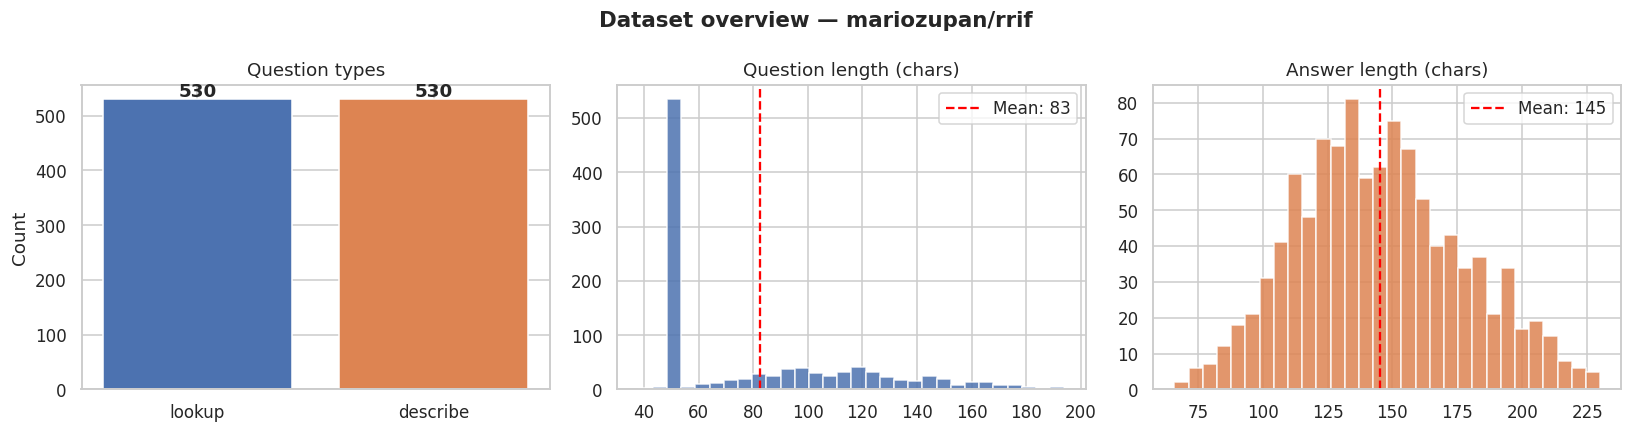

✓ Saved: data/figures/01_dataset_overview.png


In [4]:
import matplotlib, matplotlib.pyplot as plt
import seaborn as sns, pandas as pd

matplotlib.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", palette="muted")

df = pd.DataFrame(parsed)
df["q_len"] = df["question"].str.len()
df["a_len"] = df["answer_raw"].str.len()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Dataset overview — mariozupan/rrif", fontsize=14, fontweight="bold")

tc = df["q_type"].value_counts()
axes[0].bar(tc.index, tc.values, color=["#4C72B0","#DD8452","#55A868"])
axes[0].set_title("Question types")
axes[0].set_ylabel("Count")
for i, v in enumerate(tc.values):
    axes[0].text(i, v+5, str(v), ha="center", fontweight="bold")

for ax, col, color, title in [
    (axes[1], "q_len", "#4C72B0", "Question length (chars)"),
    (axes[2], "a_len", "#DD8452", "Answer length (chars)"),
]:
    ax.hist(df[col], bins=30, color=color, edgecolor="white", alpha=0.85)
    ax.axvline(df[col].mean(), color="red", linestyle="--",
               label=f"Mean: {df[col].mean():.0f}")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/figures/01_dataset_overview.png", bbox_inches="tight", dpi=150)
plt.show()
print(f"✓ Saved: {DATA_DIR}/figures/01_dataset_overview.png")


---
## ✂️ Evaluation set

Since each account is unique and RAG corpora are built from independent sources
(not the Q&A dataset itself), we use **all 1,060 questions** as the evaluation set.
No train/test split of the knowledge base is required or appropriate.


In [5]:
lookup_qs   = [p for p in parsed if p["q_type"] == "lookup"]
describe_qs = [p for p in parsed if p["q_type"] == "describe"]
test_set    = lookup_qs + describe_qs

print(f"✓ Evaluation set: {len(test_set)} questions")
print(f"  lookup:   {len(lookup_qs)}")
print(f"  describe: {len(describe_qs)}")


✓ Evaluation set: 1060 questions
  lookup:   530
  describe: 530


---
## 📄 Parse RRiF PDF → Corpus B documents

Extract all account entries from the RRiF-ov računski plan (XXVIII. edition, 2025)
and build hierarchical RAG documents with Croatian names and parent context.


In [9]:
import subprocess
subprocess.run(
    ["pip", "install", "-q", "--root-user-action=ignore", "pypdf"],
    capture_output=True
)

CompletedProcess(args=['pip', 'install', '-q', '--root-user-action=ignore', 'pypdf'], returncode=0, stdout=b'', stderr=b'\x1bDEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/dill-0.3.9-py3.12.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330\x1b\x1b\n\x1b\x1bDEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/looseversion-1.3.0-py3.12.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330\x1b\x1b\n\x1b\x1bDEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/lightning_thunder-0.2.2.dev0-py3.12.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://githu

In [10]:
import re
from pypdf import PdfReader

print(f"Učitavam PDF: {RRIF_PDF_PATH}")
reader = PdfReader(RRIF_PDF_PATH)
print(f"  Stranica: {len(reader.pages)}")

# Izvuci tekst iz svih stranica
pdf_lines = []
for page in reader.pages:
    text = page.extract_text()
    if text:
        pdf_lines.extend(text.splitlines())

pdf_text = "\n".join(pdf_lines)
print(f"✓ PDF učitan — {len(pdf_lines)} redaka")


Učitavam PDF: RRIF-RP2025.pdf
  Stranica: 45
✓ PDF učitan — 2616 redaka


In [13]:
def get_level(kljuc):
    n = len(kljuc)
    if n == 1: return "razred"
    if n == 2: return "skupina"
    if n == 3: return "sinteticki"
    if n == 4: return "analiticki"
    return "subanaliticki"

# Novi regex — jedan ili više razmaka između konta i naziva
pattern = re.compile(r'^(\d{1,6})\s+(.+)$')

raw_entries = []
i = 0
while i < len(pdf_lines):
    line = pdf_lines[i].strip()
    m = pattern.match(line)
    if m:
        kljuc = m.group(1).strip()
        naziv = m.group(2).strip()
        # Provjeri nastavlja li se naziv u sljedećem retku
        while i + 1 < len(pdf_lines):
            next_line = pdf_lines[i+1].strip()
            # Nastavak ako sljedeći redak ne počinje brojem konta
            if next_line and not pattern.match(next_line):
                # Ali ne smije biti header (sve caps bez broja)
                first_char = next_line[0] if next_line else ''
                if first_char.islower() or first_char in 'šđčćž(' \
                   or (first_char.isupper() and not next_line.isupper()):
                    # Provjeri da nije novi konto bez broja (samo naziv razreda)
                    if not re.match(r'^[A-ZŠĐČĆŽ\s,]+$', next_line):
                        naziv += ' ' + next_line
                        i += 1
                    else:
                        break
                else:
                    break
            else:
                break
        raw_entries.append({
            "kljuc": kljuc,
            "naziv": naziv,
            "razina": get_level(kljuc)
        })
    i += 1

hierarchy    = {e["kljuc"]: e["naziv"] for e in raw_entries}
level_counts = Counter(e["razina"] for e in raw_entries)
print(f"✓ Parsed {len(raw_entries)} entries")
print("  By level:")
for lvl, n in sorted(level_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"    {lvl:15s}: {n}")
print()
print("Primjeri:")
for e in raw_entries[:5]:
    print(f"  {e['kljuc']:8s} {e['naziv'][:70]}")

✓ Parsed 2473 entries
  By level:
    analiticki     : 1547
    sinteticki     : 534
    subanaliticki  : 300
    skupina        : 81
    razred         : 11

Primjeri:
  10000    Zagreb, Vlaška 68, HRVATSKA Telefon: 01/4699-760, pretplata Internet: 
  0        POTRAŽIVANJA ZA UPISANI KAPITAL I DUGOTRAJNA
  00       POTRAŽIVANJA ZA UPISANI A NEUPLAĆENI KAPITAL
  000      Potraživanja za upisani a neuplaćeni dionički kapital (analitika po up
  001      Potraživanja iz ponovljene emisije dionica za upisane a neuplaćene svo


In [16]:
# Deduplikacija po ID-u
seen     = set()
unique   = []
for doc in corpus_b_docs:
    if doc["id"] not in seen:
        seen.add(doc["id"])
        unique.append(doc)

print(f"  Duplikati uklonjeni: {len(corpus_b_docs) - len(unique)}")
corpus_b_docs = unique
print(f"✓ Corpus B (deduplicirani): {len(corpus_b_docs)} dokumenta")

  Duplikati uklonjeni: 11
✓ Corpus B (deduplicirani): 2462 dokumenta


In [17]:
def build_corpus_b_doc(entry):
    kljuc  = entry["kljuc"]
    naziv  = entry["naziv"]
    razina = entry["razina"]
    parts  = [f"Konto: {kljuc}", f"Naziv: {naziv}", f"Razina: {razina}"]
    if razina == "skupina":
        r = hierarchy.get(kljuc[:1], "")
        if r: parts.append(f"Razred: {kljuc[:1]} — {r}")
    elif razina == "sinteticki":
        sk = hierarchy.get(kljuc[:2], "")
        r  = hierarchy.get(kljuc[:1], "")
        if sk: parts.append(f"Skupina: {kljuc[:2]} — {sk}")
        if r:  parts.append(f"Razred: {kljuc[:1]} — {r}")
    elif razina == "analiticki":
        syn = hierarchy.get(kljuc[:3], "")
        sk  = hierarchy.get(kljuc[:2], "")
        if syn: parts.append(f"Sintetički: {kljuc[:3]} — {syn}")
        if sk:  parts.append(f"Skupina: {kljuc[:2]} — {sk}")
    elif razina == "subanaliticki":
        syn = hierarchy.get(kljuc[:3], "")
        if syn: parts.append(f"Sintetički: {kljuc[:3]} — {syn}")
    return {
        "id":       f"rrif_{kljuc}",
        "kljuc":    kljuc,
        "razina":   razina,
        "text":     "\n".join(parts),
        "metadata": {"kljuc": kljuc, "naziv": naziv, "razina": razina},
    }

corpus_b_docs = [build_corpus_b_doc(e) for e in raw_entries]
print(f"✓ Corpus B: {len(corpus_b_docs)} documents")
print()
print("Example (sintetički):")
print("-" * 60)
sin = [d for d in corpus_b_docs if d["razina"] == "sinteticki"]
print(sin[0]["text"])
print("-" * 60)


✓ Corpus B: 2473 documents

Example (sintetički):
------------------------------------------------------------
Konto: 000
Naziv: Potraživanja za upisani a neuplaćeni dionički kapital (analitika po upisnicima)
Razina: sinteticki
Skupina: 00 — POTRAŽIVANJA ZA UPISANI A NEUPLAĆENI KAPITAL
Razred: 0 — POTRAŽIVANJA ZA UPISANI KAPITAL I DUGOTRAJNA
------------------------------------------------------------


In [18]:
# Deduplikacija po ID-u
seen     = set()
unique   = []
for doc in corpus_b_docs:
    if doc["id"] not in seen:
        seen.add(doc["id"])
        unique.append(doc)

print(f"  Duplikati uklonjeni: {len(corpus_b_docs) - len(unique)}")
corpus_b_docs = unique
print(f"✓ Corpus B (deduplicirani): {len(corpus_b_docs)} dokumenta")

  Duplikati uklonjeni: 11
✓ Corpus B (deduplicirani): 2462 dokumenta


---
## 💾 Save artefacts

In [19]:
# Coverage check
zupan_accounts  = {p["answer"].get("account_number","")
                   for p in parsed if isinstance(p["answer"], dict)}
rrif_sinteticki = {e["kljuc"] for e in raw_entries if e["razina"] == "sinteticki"}
coverage        = len(zupan_accounts & rrif_sinteticki) / len(zupan_accounts) * 100

# Save
with open(f"{DATA_DIR}/test_set.json", "w", encoding="utf-8") as f:
    json.dump(test_set, f, ensure_ascii=False, indent=2)

with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", "w", encoding="utf-8") as f:
    json.dump(corpus_b_docs, f, ensure_ascii=False, indent=2)

stats = {
    "dataset": {
        "total":           len(parsed),
        "lookup":          len(lookup_qs),
        "describe":        len(describe_qs),
        "unique_accounts": len(account_counts),
    },
    "corpus_b": {
        "total_docs":         len(corpus_b_docs),
        "by_level":           dict(level_counts),
        "zupan_coverage_pct": round(coverage, 2),
    },
}
with open(f"{DATA_DIR}/stats.json", "w") as f:
    json.dump(stats, f, indent=2)

print("✓ Saved:")
print(f"  data/test_set.json             ({len(test_set)} questions)")
print(f"  data/corpus_b_rrif_documents.json ({len(corpus_b_docs)} docs)")
print(f"  data/stats.json")
print(f"  Župan → RRiF coverage: {coverage:.1f}%")
print()
print("Next: 02_build_vectordb_corpus_a.ipynb")


✓ Saved:
  data/test_set.json             (1060 questions)
  data/corpus_b_rrif_documents.json (2462 docs)
  data/stats.json
  Župan → RRiF coverage: 99.6%

Next: 02_build_vectordb_corpus_a.ipynb
